In [1]:
from google.colab import drive

In [2]:
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
ls drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/2_exploratory_data_analysis

startup_funding.csv  startup_funding.ipynb


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
pip install IPython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 62.4 MB/s  0:00:00


In [8]:
from IPython.display import display

In [9]:
df=pd.read_csv("drive/MyDrive/Colab_Notebooks/A_DREAM_JOB/2_exploratory_data_analysis/startup_funding.csv")

In [10]:
display(df.head())

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
0,1,09/01/2020,BYJU’S,E-Tech,E-learning,Bengaluru,Tiger Global Management,Private Equity Round,"20,00,00,000",NaN
1,2,13/01/2020,Shuttl,Transportation,App based shuttle service,Gurgaon,Susquehanna Growth Equity,Series C,"80,48,394",NaN
2,3,09/01/2020,Mamaearth,E-commerce,Retailer of baby and toddler products,Bengaluru,Sequoia Capital India,Series B,"1,83,58,860",NaN
3,4,02/01/2020,https://www.wealthbucket.in/,FinTech,Online Investment,New Delhi,Vinod Khatumal,Pre-series A,"30,00,000",NaN
4,5,02/01/2020,Fashor,Fashion and Apparel,Embroiled Clothes For Women,Mumbai,Sprout Venture Partners,Seed Round,"18,00,000",NaN


### What information do we have, and how much data is available?

In [11]:
print("Dataset Shape:", df.shape)
print("Total Records:", len(df))
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nSample Records:")
display(df.sample(min(5, len(df)), random_state=42))

Dataset Shape: (3044, 10)
Total Records: 3044
Total Columns: 10

Column Names:
['Sr No', 'Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical', 'SubVertical', 'City  Location', 'Investors Name', 'InvestmentnType', 'Amount in USD', 'Remarks']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3044 entries, 0 to 3043
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Sr No              3044 non-null   int64 
 1   Date dd/mm/yyyy    3044 non-null   object
 2   Startup Name       3044 non-null   object
 3   Industry Vertical  2873 non-null   object
 4   SubVertical        2108 non-null   object
 5   City  Location     2864 non-null   object
 6   Investors Name     3020 non-null   object
 7   InvestmentnType    3040 non-null   object
 8   Amount in USD      2084 non-null   object
 9   Remarks            419 non-null    object
dtypes: int64(1), object(9)
memory usage: 237.9+ KB

Sample Reco

,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
298,299,18/04/2018,Coverfox,Consumer Internet,Online Insurance Aggregator,Mumbai,"International Finance Corporation, Transameric...",Private Equity,"2,20,00,000",NaN
2792,2793,20/05/2015,Lookup,B2C Messaging App,NaN,Bangalore,Biz Stone,Private Equity,"30,00,000",Series A
139,140,22/11/2018,Skillbox,Social Network,Art,Gurugram,Individual investors,Seed Funding,Undisclosed,NaN
535,536,09/10/2017,MyGubbi,eCommerce,Home Interior Designing Seller,Bangalore,"Firoze Irani, Vipul Parekh, Ananda Kallugadde,...",Private Equity,"27,00,000",NaN
945,946,07/03/2017,Data Resolve,Technology,Cyber Security Solutions,Noida,IDFC Parampara Early Stage Opportunities Fund,Private Equity,"10,00,000",NaN


### Which columns can we analyze statistically?

In [12]:
display(df.describe(include="all").T)

print("\nColumn Data Types:")
display(df.dtypes.to_frame("Data Type"))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Sr No,3044.0,NaN,NaN,NaN,1522.5,878.871435,1.0,761.75,1522.5,2283.25,3044.0
Date dd/mm/yyyy,3044,1035,30/11/2016,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Startup Name,3044,2459,Swiggy,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Industry Vertical,2873,821,Consumer Internet,941,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SubVertical,2108,1942,Online Lending Platform,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City Location,2864,112,Bangalore,700,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Investors Name,3020,2412,Undisclosed Investors,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InvestmentnType,3040,55,Private Equity,1356,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Amount in USD,2084,471,"10,00,000",165,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Remarks,419,72,Series A,175,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Column Data Types:


,Data Type
Sr No,int64
Date dd/mm/yyyy,object
Startup Name,object
Industry Vertical,object
SubVertical,object
City Location,object
Investors Name,object
InvestmentnType,object
Amount in USD,object
Remarks,object


### Are there missing values, duplicate transactions, or inconsistent data types?

In [13]:
audit = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null": df.notna().sum(),
    "Missing": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique(dropna=True)
})

display(audit.sort_values("Missing %", ascending=False))

print("Duplicate Rows:", df.duplicated().sum())

,Data Type,Non-Null,Missing,Missing %,Unique Values
Remarks,object,419,2625,86.24,72
Amount in USD,object,2084,960,31.54,471
SubVertical,object,2108,936,30.75,1942
City Location,object,2864,180,5.91,112
Industry Vertical,object,2873,171,5.62,821
Investors Name,object,3020,24,0.79,2412
InvestmentnType,object,3040,4,0.13,55
Sr No,int64,3044,0,0.00,3044
Date dd/mm/yyyy,object,3044,0,0.00,1035
Startup Name,object,3044,0,0.00,2459


Duplicate Rows: 0


In [14]:
missing = df.isna().mean().mul(100)
high_missing = missing[missing > 20]

print("=== INITIAL DATA SCIENCE ASSESSMENT ===")

print(f"Total observations: {len(df):,}")
print(f"Total features: {df.shape[1]}")
print(f"Duplicate records: {df.duplicated().sum():,}")

print(f"Columns with >20% missing data: {len(high_missing)}")

if not high_missing.empty:
    print("\nColumns requiring investigation:")
    for col, pct in high_missing.items():
        print(f"- {col}: {pct:.2f}% missing")

print("\nNext action:")
print("Investigate missing values, inconsistent formats,")
print("and duplicates before performing funding analysis.")

=== INITIAL DATA SCIENCE ASSESSMENT ===
Total observations: 3,044
Total features: 10
Duplicate records: 0
Columns with >20% missing data: 3

Columns requiring investigation:
- SubVertical: 30.75% missing
- Amount in USD: 31.54% missing
- Remarks: 86.24% missing

Next action:
Investigate missing values, inconsistent formats,
and duplicates before performing funding analysis.


### Which startup funding attributes have incomplete information?

In [15]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2)
})

display(
    missing_report
    .query("`Missing Count` > 0")
    .sort_values("Missing %", ascending=False)
)

,Missing Count,Missing %
Remarks,2625,86.24
Amount in USD,960,31.54
SubVertical,936,30.75
City Location,180,5.91
Industry Vertical,171,5.62
Investors Name,24,0.79
InvestmentnType,4,0.13


### Is missing information concentrated in particular columns?

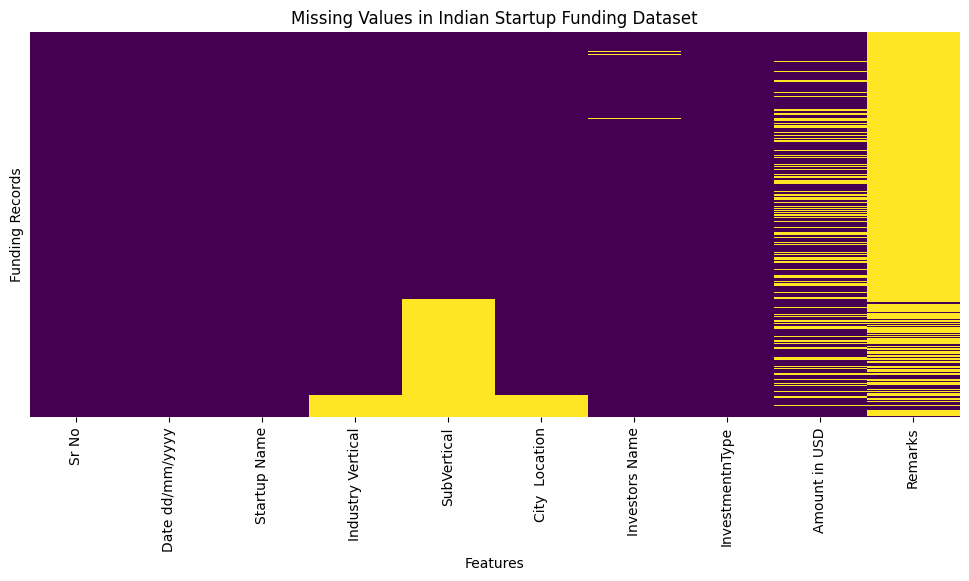

In [16]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in Indian Startup Funding Dataset")
plt.xlabel("Features")
plt.ylabel("Funding Records")
plt.show()

### How many funding transactions lack an investment amount, and what proportion of the dataset do they represent?

In [17]:
amount_col = next(
    (col for col in df.columns
     if "amount" in col.lower()),
    None
)

if amount_col is not None:
    amount = df[amount_col].astype("string").str.strip()

    missing_amount = (
        amount.isna()
        | amount.str.lower().isin(
            ["", "undisclosed", "unknown", "n/a", "nan", "-"]
        ).fillna(False)
    )

    print("Investment Amount Column:", amount_col)
    print("Missing/Undisclosed Records:", missing_amount.sum())
    print("Missing %:", round(missing_amount.mean() * 100, 2))

    display(df.loc[missing_amount].head(10))
else:
    print("No investment amount column detected.")

Investment Amount Column: Amount in USD
Missing/Undisclosed Records: 967
Missing %: 31.77


,Sr No,Date dd/mm/yyyy,Startup Name,Industry Vertical,SubVertical,City Location,Investors Name,InvestmentnType,Amount in USD,Remarks
20,21,17/11/2019,Burger Singh,Food and Beverage,Indian Burger Brand,Gurgaon,RB Investments,Venture,undisclosed,NaN
34,35,21/10/2019,The Man Company,Consumer Goods,Beauty and Grooming,Gurgaon,Ayushmann Khurana,Corporate Round,unknown,NaN
58,59,19/08/2019,Mishry Reviews,Services,Product Review,Gurgaon,Vir Sanghvi,Series A,Undisclosed,NaN
89,90,06/05/2019,Ola Electric,Transport,Cabs,Bengaluru,Tata Sons,Series A,undisclosed,NaN
91,92,05/05/2019,StyleDotMe,E-commerce,Fashion and Shopping,Delhi,Indian Angel Network and other angel investors...,Bridge Round,undisclosed,NaN
112,113,01/02/2019,FleetX,AI,Logistics,Gurgaon,India Quotient and LetsVenture\\xe2\\x80\\x99s...,Pre Series A,Undisclosed,NaN
139,140,22/11/2018,Skillbox,Social Network,Art,Gurugram,Individual investors,Seed Funding,Undisclosed,NaN
144,145,01/10/2018,Northmist,Fashion,Mens Wear,Delhi,Prashant Jaiswal,Seed/ Angel Funding,NaN,NaN
155,156,04/09/2018,HappyGoEasy,Consumer Internet,Online Travel Agecy,Gurugram,"Korea Investment Partners (KIP), Samsung and C...",Private Equity,NaN,NaN
157,158,05/09/2018,Mad Street Den,Technology,Computer Vision And Artificial Intelligence (A...,Chennai,KDDI\\xc2\\xa0,Private Equity,NaN,NaN


### Let's implement safe categorical cleaning.

In [18]:
df_clean = df.copy()

categorical_cols = df_clean.select_dtypes(
    include=["object", "string", "category"]
).columns

for col in categorical_cols:
    df_clean[col] = df_clean[col].replace(
        r"^\s*$", np.nan, regex=True
    )

    if "amount" not in col.lower() and "date" not in col.lower():
        df_clean[col] = df_clean[col].fillna("Unknown")

print("Categorical missing values handled.")

Categorical missing values handled.


### Did we preserve the original transactions while improving data completeness?

In [19]:
comparison = pd.DataFrame({
    "Before": df.isnull().sum(),
    "After": df_clean.isnull().sum()
})

display(comparison)

print("Original Records:", len(df))
print("Cleaned Records:", len(df_clean))
print("Records Preserved:", len(df) == len(df_clean))

,Before,After
Sr No,0,0
Date dd/mm/yyyy,0,0
Startup Name,0,0
Industry Vertical,171,0
SubVertical,936,0
City Location,180,0
Investors Name,24,0
InvestmentnType,4,0
Amount in USD,960,960
Remarks,2625,0


Original Records: 3044
Cleaned Records: 3044
Records Preserved: True


In [20]:
print("=== MISSING VALUES: DATA SCIENTIST CONCLUSION ===")

original_missing = df.isnull().sum().sum()
remaining_missing = df_clean.isnull().sum().sum()

print(f"Original missing cells: {original_missing:,}")
print(f"Remaining missing cells: {remaining_missing:,}")
print(f"Records preserved: {len(df_clean):,} / {len(df):,}")

if amount_col:
    print(f"\nFunding amount missing/undisclosed: {missing_amount.sum():,}")
    print("Impact: These records cannot support numerical funding totals.")

print("\nDecision:")
print("Retain transactions, label unknown categories,")
print("and exclude unavailable financial amounts from monetary analysis.")

=== MISSING VALUES: DATA SCIENTIST CONCLUSION ===
Original missing cells: 4,900
Remaining missing cells: 960
Records preserved: 3,044 / 3,044

Funding amount missing/undisclosed: 967
Impact: These records cannot support numerical funding totals.

Decision:
Retain transactions, label unknown categories,
and exclude unavailable financial amounts from monetary analysis.


### Prepare funding amounts for numerical analysis

In [21]:
# Start from our Step 2 cleaned dataset
df_out = df_clean.copy()

amount_col = next(
    col for col in df_out.columns
    if "amount" in col.lower()
)

# Convert USD amounts into numeric values
df_out["Funding_USD"] = pd.to_numeric(
    df_out[amount_col]
      .astype("string")
      .str.replace(",", "", regex=False)
      .str.replace("$", "", regex=False)
      .str.strip(),
    errors="coerce"
)

# Exclude missing, zero, and negative funding
funding = df_out.loc[
    df_out["Funding_USD"].notna()
    & (df_out["Funding_USD"] > 0)
].copy()

print("Total Records:", len(df_out))
print("Valid Funding Records:", len(funding))
print("Excluded from numerical analysis:", len(df_out) - len(funding))

display(funding["Funding_USD"].describe())

Total Records: 3044
Valid Funding Records: 2065
Excluded from numerical analysis: 979


,Funding_USD
count,2065.0
mean,18429897.270809
std,121373444.127594
min,16000.0
25%,470000.0
50%,1700000.0
75%,8000000.0
max,3900000000.0


### Which funding transactions are unusually large compared with typical investments?

In [22]:
Q1 = funding["Funding_USD"].quantile(0.25)
Q3 = funding["Funding_USD"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

funding["Is_Outlier"] = (
    (funding["Funding_USD"] < lower) |
    (funding["Funding_USD"] > upper)
)

print(f"Q1: ${Q1:,.2f}")
print(f"Q3: ${Q3:,.2f}")
print(f"IQR: ${IQR:,.2f}")
print(f"Upper Outlier Threshold: ${upper:,.2f}")
print("Outliers Detected:", funding["Is_Outlier"].sum())
print("Outlier Percentage:", round(funding["Is_Outlier"].mean() * 100, 2))

Q1: $470,000.00
Q3: $8,000,000.00
IQR: $7,530,000.00
Upper Outlier Threshold: $19,295,000.00
Outliers Detected: 283
Outlier Percentage: 13.7


### Which startups received the biggest disclosed funding amounts?

In [23]:
startup_col = next(
    (col for col in funding.columns
     if "startup" in col.lower()),
    None
)

columns = (
    [startup_col, "Funding_USD", "Is_Outlier"]
    if startup_col else
    ["Funding_USD", "Is_Outlier"]
)

display(
    funding[columns]
    .sort_values("Funding_USD", ascending=False)
    .head(10)
)

,Startup Name,Funding_USD,Is_Outlier
60,Rapido Bike Taxi,3900000000.0,True
651,Flipkart,2500000000.0,True
966,Flipkart,1400000000.0,True
830,Paytm,1400000000.0,True
31,Paytm,1000000000.0,True
2648,Flipkart.com,700000000.0,True
2459,Paytm,680000000.0,True
188,True North,600000000.0,True
33,Udaan,585000000.0,True
2470,Snapdeal,500000000.0,True


### How far do the largest investments deviate from the typical funding range?

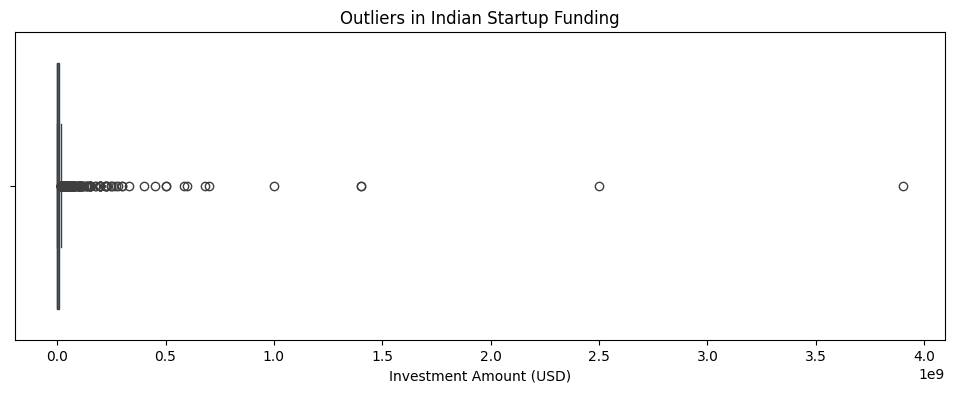

In [24]:
plt.figure(figsize=(12, 4))

sns.boxplot(
    x=funding["Funding_USD"]
)

plt.title("Outliers in Indian Startup Funding")
plt.xlabel("Investment Amount (USD)")
plt.show()

### How large are investments in the top 5% and top 1%?

In [25]:
percentiles = funding["Funding_USD"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

display(
    percentiles.to_frame("Funding_USD")
)

p95 = funding["Funding_USD"].quantile(0.95)
p99 = funding["Funding_USD"].quantile(0.99)

print(f"95th Percentile: ${p95:,.2f}")
print(f"99th Percentile: ${p99:,.2f}")

top_1_percent = funding[
    funding["Funding_USD"] >= p99
]

display(
    top_1_percent[columns]
    .sort_values("Funding_USD", ascending=False)
    .head(10)
)

,Funding_USD
0.50,1700000.0
0.75,8000000.0
0.90,28600000.0
0.95,60000000.0
0.99,237839999.999998


95th Percentile: $60,000,000.00
99th Percentile: $237,840,000.00


,Startup Name,Funding_USD,Is_Outlier
60,Rapido Bike Taxi,3900000000.0,True
651,Flipkart,2500000000.0,True
830,Paytm,1400000000.0,True
966,Flipkart,1400000000.0,True
31,Paytm,1000000000.0,True
2648,Flipkart.com,700000000.0,True
2459,Paytm,680000000.0,True
188,True North,600000000.0,True
33,Udaan,585000000.0,True
2244,Ola,500000000.0,True


### Do exceptionally large investments distort average startup funding?

In [26]:
normal = funding.loc[
    ~funding["Is_Outlier"],
    "Funding_USD"
]

comparison = pd.DataFrame({
    "Metric": [
        "Mean Funding",
        "Median Funding",
        "Maximum Funding",
        "Records"
    ],
    "All Investments": [
        funding["Funding_USD"].mean(),
        funding["Funding_USD"].median(),
        funding["Funding_USD"].max(),
        len(funding)
    ],
    "Without IQR Outliers": [
        normal.mean(),
        normal.median(),
        normal.max(),
        len(normal)
    ]
})

display(comparison)

,Metric,All Investments,Without IQR Outliers
0,Mean Funding,1.842990e+07,3.159511e+06
1,Median Funding,1.700000e+06,1.000000e+06
2,Maximum Funding,3.900000e+09,1.900000e+07
3,Records,2.065000e+03,1.782000e+03


In [27]:
total_funding = funding["Funding_USD"].sum()

outlier_funding = funding.loc[
    funding["Is_Outlier"], "Funding_USD"
].sum()

outlier_share = (
    outlier_funding / total_funding * 100
    if total_funding > 0 else np.nan
)

mean_funding = funding["Funding_USD"].mean()
median_funding = funding["Funding_USD"].median()

print("=== DATA SCIENTIST CONCLUSION ===")

print(f"Valid Funding Transactions: {len(funding):,}")
print(f"IQR Outliers: {funding['Is_Outlier'].sum():,}")
print(f"Outlier Funding Share: {outlier_share:.2f}%")
print(f"Mean Investment: ${mean_funding:,.2f}")
print(f"Median Investment: ${median_funding:,.2f}")

if mean_funding > median_funding:
    print("\nFinding 1: Funding amounts are positively skewed by the mean-median measure.")
else:
    print("\nFinding 1: Mean funding does not exceed median funding.")

if outlier_share > 50:
    print("Finding 2: IQR outliers account for the majority of disclosed funding.")
else:
    print("Finding 2: IQR outliers account for less than half of disclosed funding.")

print("\nRecommendation:")
print("Preserve legitimate large investments.")
print("Use median alongside mean to describe typical funding.")
print("Investigate suspicious records before excluding them.")

=== DATA SCIENTIST CONCLUSION ===
Valid Funding Transactions: 2,065
IQR Outliers: 283
Outlier Funding Share: 85.21%
Mean Investment: $18,429,897.27
Median Investment: $1,700,000.00

Finding 1: Funding amounts are positively skewed by the mean-median measure.
Finding 2: IQR outliers account for the majority of disclosed funding.

Recommendation:
Preserve legitimate large investments.
Use median alongside mean to describe typical funding.
Investigate suspicious records before excluding them.


### Which features explain where, how, and how much startups receive funding?

In [28]:
print("Available Columns:")
print(funding.columns.tolist())

# Automatically identify relevant columns
def find_col(keywords):
    return next(
        (col for col in funding.columns
         if any(k in col.lower() for k in keywords)),
        None
    )

city_col = find_col(["city", "location"])
industry_col = find_col(["industry", "vertical"])
type_col = find_col(["investmenttype", "investment type", "funding type"])
date_col = find_col(["date"])

print("City:", city_col)
print("Industry:", industry_col)
print("Investment Type:", type_col)
print("Date:", date_col)

Available Columns:
['Sr No', 'Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical', 'SubVertical', 'City  Location', 'Investors Name', 'InvestmentnType', 'Amount in USD', 'Remarks', 'Funding_USD', 'Is_Outlier']
City: City  Location
Industry: Industry Vertical
Investment Type: None
Date: Date dd/mm/yyyy


### Which Indian cities attract the highest total disclosed startup funding?

In [29]:
city_analysis = (
    funding.groupby(city_col, dropna=False)
    .agg(
        Total_Funding=("Funding_USD", "sum"),
        Average_Funding=("Funding_USD", "mean"),
        Median_Funding=("Funding_USD", "median"),
        Deals=("Funding_USD", "count")
    )
    .sort_values("Total_Funding", ascending=False)
)

display(city_analysis.head(10))

,Total_Funding,Average_Funding,Median_Funding,Deals
City Location,,,,
Bangalore,11361588108.0,24915763.394737,2000000.0,456
Bengaluru,7098578755.0,56337926.626984,5000000.0,126
Mumbai,4921185015.0,12272281.832918,2000000.0,401
New Delhi,3017816875.0,12522061.721992,1000000.0,241
Gurgaon,3005296134.54,15178263.305758,2000000.0,198
Unknown,1271863868.0,9421213.837037,1500000.0,135
Noida,1262864000.0,22961163.636364,1000000.0,55
Gurugram,865932523.0,20137965.651163,4000000.0,43
Chennai,718767000.0,9583560.0,2500000.0,75


### Which Indian startup sectors receive the most investment?

In [30]:
industry_analysis = (
    funding.groupby(industry_col, dropna=False)
    .agg(
        Total_Funding=("Funding_USD", "sum"),
        Average_Funding=("Funding_USD", "mean"),
        Median_Funding=("Funding_USD", "median"),
        Deals=("Funding_USD", "count")
    )
    .sort_values("Total_Funding", ascending=False)
)

display(industry_analysis.head(10))

,Total_Funding,Average_Funding,Median_Funding,Deals
Industry Vertical,,,,
Consumer Internet,6253084245.0,10616441.842105,1000000.0,589
eCommerce,5002533000.0,39702642.857143,2000000.0,126
Transportation,3916632394.0,979158098.5,6524197.0,4
Technology,2229707930.0,7192606.225806,1500000.0,310
Finance,1971438000.0,34586631.578947,6240000.0,57
ECommerce,1878797608.0,50778313.72973,5000000.0,37
Unknown,1231811368.0,9403140.21374,1500000.0,131
FinTech,1220711265.0,135634585.0,15500000.0,9
E-Commerce,1008110064.54,38773464.020769,10050000.0,26


### Which investment categories account for the largest funding amounts?

In [32]:
print(funding.columns.tolist())

['Sr No', 'Date dd/mm/yyyy', 'Startup Name', 'Industry Vertical', 'SubVertical', 'City  Location', 'Investors Name', 'InvestmentnType', 'Amount in USD', 'Remarks', 'Funding_USD', 'Is_Outlier']


In [33]:
# Identify investment type column
type_col = next(
    (col for col in funding.columns
     if "investment" in col.lower()
     or "funding type" in col.lower()),
    None
)

print("Detected Column:", type_col)

if type_col is not None:
    type_analysis = (
        funding.groupby(type_col, dropna=False)
        .agg(
            Total_Funding=("Funding_USD", "sum"),
            Median_Funding=("Funding_USD", "median"),
            Deals=("Funding_USD", "count")
        )
        .sort_values("Total_Funding", ascending=False)
    )

    display(type_analysis)
else:
    print("Investment type column not found.")

Detected Column: InvestmentnType


,Total_Funding,Median_Funding,Deals
InvestmentnType,,,
Private Equity,26642318165.0,5925000.0,1066
Series B,4799195735.0,15900000.0,20
Series D,1481799000.0,65000000.0,12
Series C,1044718394.0,50000000.0,14
Funding Round,1000000000.0,1000000000.0,1
Seed Funding,568628308.0,324500.0,716
Private Equity Round,506000000.0,150000000.0,4
Series G,231000000.0,231000000.0,1
Unknown,207629010.22,4889975.54,3


### Can we derive useful variables to understand funding scale and investment patterns?

In [34]:
# Feature 1: Funding in millions
funding["Funding_Million_USD"] = (
    funding["Funding_USD"] / 1_000_000
)

# Feature 2: Funding size categories
q33 = funding["Funding_USD"].quantile(1/3)
q67 = funding["Funding_USD"].quantile(2/3)

funding["Funding_Category"] = np.select(
    [
        funding["Funding_USD"] <= q33,
        funding["Funding_USD"] <= q67
    ],
    ["Small", "Medium"],
    default="Large"
)

# Feature 3: Investment year
funding["Funding_Date"] = pd.to_datetime(
    funding[date_col],
    errors="coerce",
    dayfirst=True
)

funding["Funding_Year"] = funding["Funding_Date"].dt.year

display(
    funding[
        ["Funding_USD", "Funding_Million_USD",
         "Funding_Category", "Funding_Year"]
    ].head(10)
)

,Funding_USD,Funding_Million_USD,Funding_Category,Funding_Year
0,200000000.0,200.0,Large,2020.0
1,8048394.0,8.048394,Large,2020.0
2,18358860.0,18.35886,Large,2020.0
3,3000000.0,3.0,Medium,2020.0
4,1800000.0,1.8,Medium,2020.0
5,9000000.0,9.0,Large,2020.0
6,150000000.0,150.0,Large,2020.0
7,6000000.0,6.0,Large,2019.0
8,70000000.0,70.0,Large,2019.0
9,50000000.0,50.0,Large,2019.0


### How has disclosed startup funding changed across the years represented in the dataset?

In [35]:
yearly_analysis = (
    funding.dropna(subset=["Funding_Year"])
    .groupby("Funding_Year")
    .agg(
        Total_Funding=("Funding_USD", "sum"),
        Average_Funding=("Funding_USD", "mean"),
        Deals=("Funding_USD", "count")
    )
    .sort_index()
)

yearly_analysis["Funding_Billion_USD"] = (
    yearly_analysis["Total_Funding"] / 1_000_000_000
)

display(yearly_analysis)

,Total_Funding,Average_Funding,Deals,Funding_Billion_USD
Funding_Year,,,,
2015.0,8597207368.0,13391288.735202,642,8.597207
2016.0,3828088608.0,6532574.416382,586,3.828089
2017.0,10429309730.0,22871293.267544,456,10.42931
2018.0,5116118369.0,19379236.246212,264,5.116118
2019.0,9686576535.219999,93140158.9925,104,9.686577
2020.0,390207254.0,55743893.428571,7,0.390207


### Are years associated with larger disclosed funding amounts?

,Funding_Year,Funding_Million_USD
Funding_Year,1.000000,0.178512
Funding_Million_USD,0.178512,1.000000


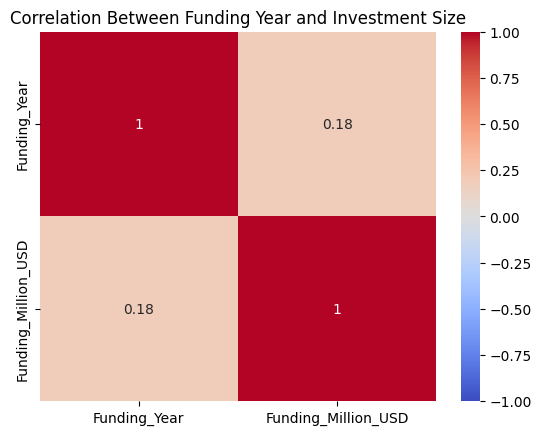

In [36]:
correlation_data = funding[
    ["Funding_Year", "Funding_Million_USD"]
].dropna()

correlation = correlation_data.corr(method="spearman")

display(correlation)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Funding Year and Investment Size")
plt.show()

### What are our strongest findings about India's startup funding ecosystem?

In [37]:
print("=== FEATURE ANALYSIS: DATA SCIENTIST CONCLUSION ===")

# Finding 1: Leading city
top_city = city_analysis.iloc[0]
print(
    f"1. Leading City: {city_analysis.index[0]} "
    f"(${top_city['Total_Funding']:,.0f} disclosed funding)"
)

# Finding 2: Leading industry
top_industry = industry_analysis.iloc[0]
print(
    f"2. Leading Industry: {industry_analysis.index[0]} "
    f"(${top_industry['Total_Funding']:,.0f})"
)

# Finding 3: Leading investment type
top_type = type_analysis.iloc[0]
print(
    f"3. Leading Investment Type: {type_analysis.index[0]} "
    f"({int(top_type['Deals']):,} disclosed deals)"
)

# Finding 4: Highest funding year
if not yearly_analysis.empty:
    peak_year = yearly_analysis["Total_Funding"].idxmax()
    print(f"4. Highest Disclosed Funding Year: {int(peak_year)}")

# Finding 5: Concentration of funding
top_5_share = (
    city_analysis["Total_Funding"].head(5).sum()
    / city_analysis["Total_Funding"].sum() * 100
)

print(f"5. Top 5 Cities Funding Share: {top_5_share:.2f}%")

print("\nRECOMMENDATION:")
print("Investigate geographic and sector concentration.")
print("Compare median funding and deal volume alongside totals.")
print("Validate data coverage before making ecosystem-wide claims.")

=== FEATURE ANALYSIS: DATA SCIENTIST CONCLUSION ===
1. Leading City: Bangalore ($11,361,588,108 disclosed funding)
2. Leading Industry: Consumer Internet ($6,253,084,245)
3. Leading Investment Type: Private Equity (1,066 disclosed deals)
4. Highest Disclosed Funding Year: 2017
5. Top 5 Cities Funding Share: 77.26%

RECOMMENDATION:
Investigate geographic and sector concentration.
Compare median funding and deal volume alongside totals.
Validate data coverage before making ecosystem-wide claims.


### Which Indian cities attract the highest disclosed startup investment?


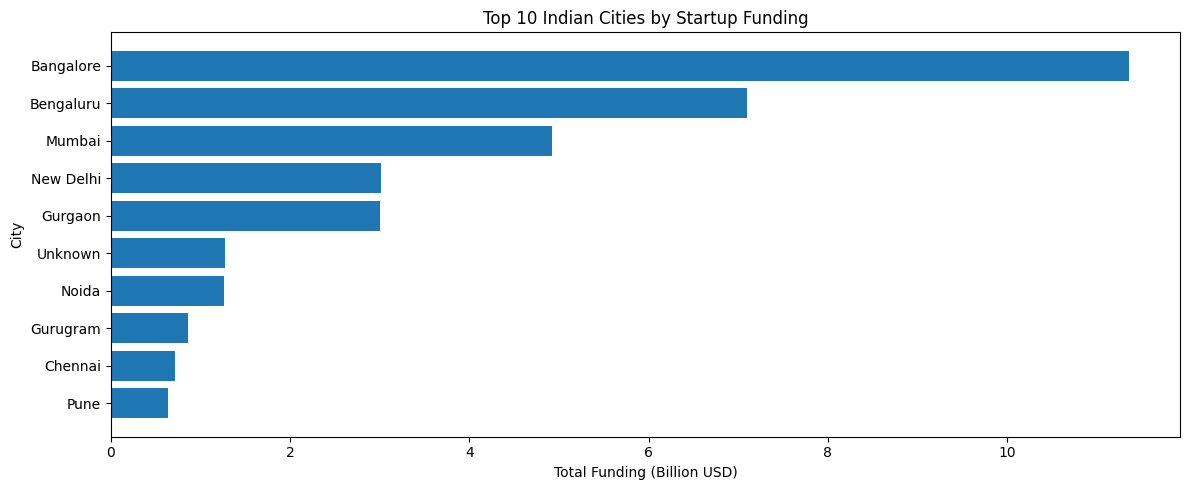

In [38]:
plt.figure(figsize=(12, 5))

top_cities = city_analysis.head(10).sort_values("Total_Funding")

plt.barh(
    top_cities.index.astype(str),
    top_cities["Total_Funding"] / 1e9
)

plt.title("Top 10 Indian Cities by Startup Funding")
plt.xlabel("Total Funding (Billion USD)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

### Which industries attract the most startup investment?

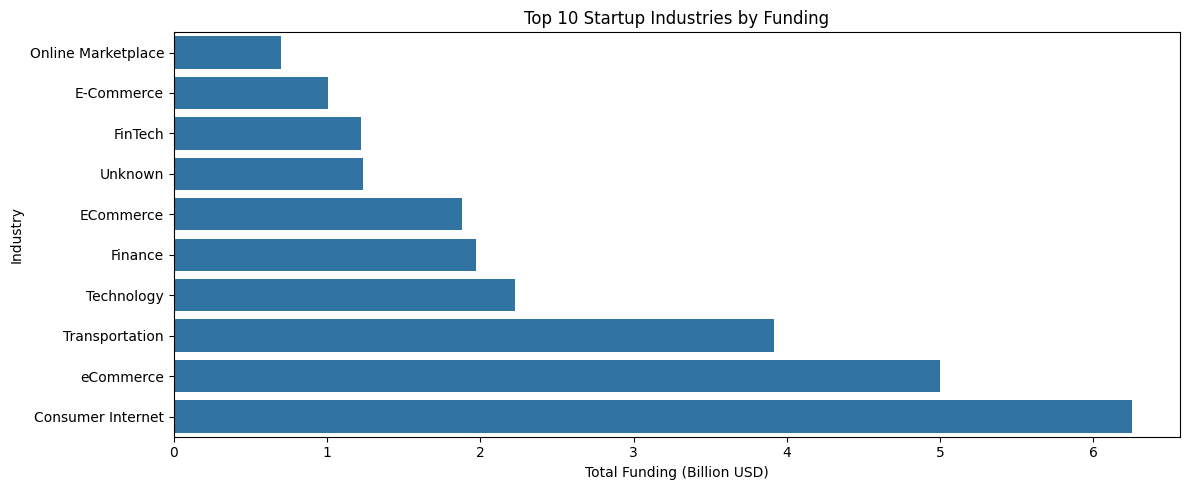

In [39]:
plt.figure(figsize=(12, 5))

top_industries = industry_analysis.head(10).sort_values("Total_Funding")

sns.barplot(
    x=top_industries["Total_Funding"] / 1e9,
    y=top_industries.index.astype(str)
)

plt.title("Top 10 Startup Industries by Funding")
plt.xlabel("Total Funding (Billion USD)")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

### How has startup funding changed over time?

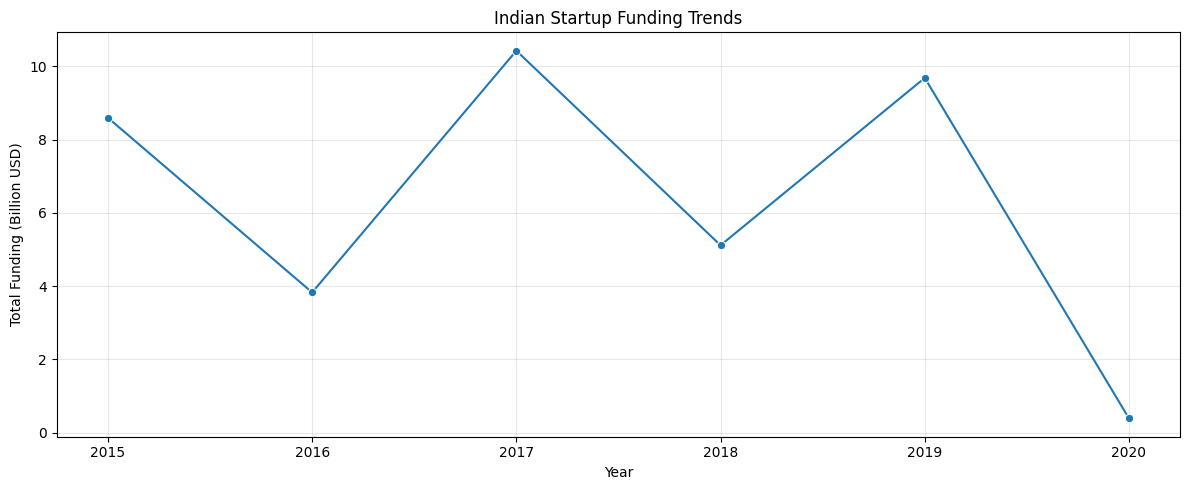

In [40]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=yearly_analysis.reset_index(),
    x="Funding_Year",
    y="Funding_Billion_USD",
    marker="o"
)

plt.title("Indian Startup Funding Trends")
plt.xlabel("Year")
plt.ylabel("Total Funding (Billion USD)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Are most startup investments relatively small, or are large investments common?

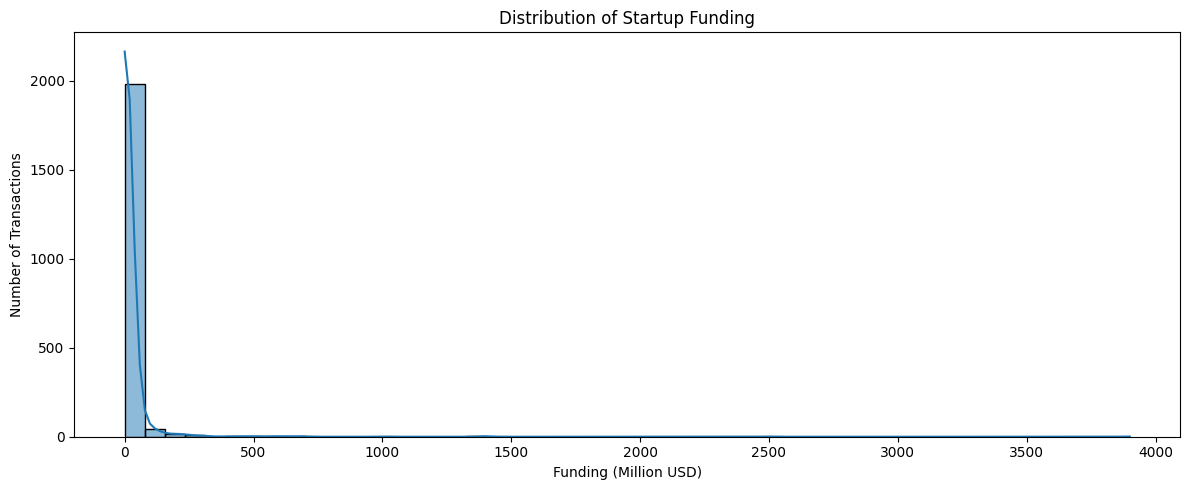

In [41]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=funding,
    x="Funding_Million_USD",
    bins=50,
    kde=True
)

plt.title("Distribution of Startup Funding")
plt.xlabel("Funding (Million USD)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

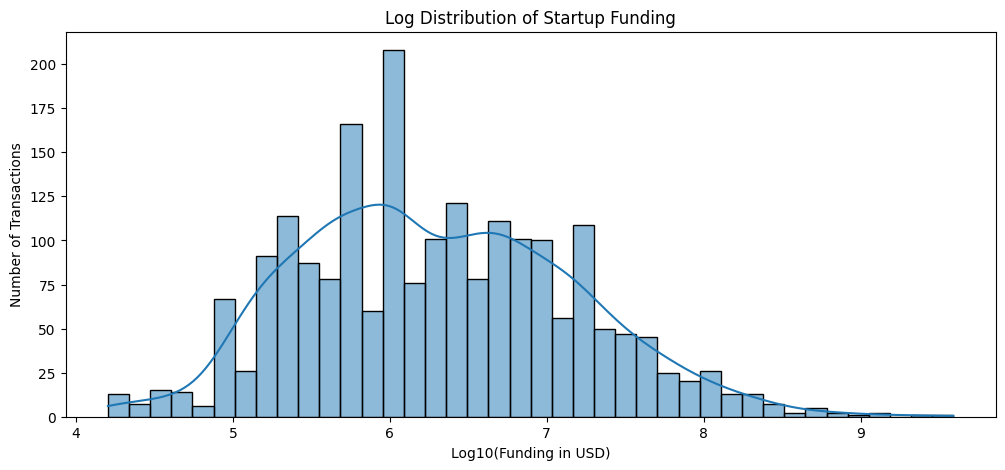

In [42]:
plt.figure(figsize=(12, 5))

sns.histplot(
    np.log10(funding["Funding_USD"]),
    bins=40,
    kde=True
)

plt.title("Log Distribution of Startup Funding")
plt.xlabel("Log10(Funding in USD)")
plt.ylabel("Number of Transactions")
plt.show()

### Which leading startup cities have larger typical investments and greater funding variability?

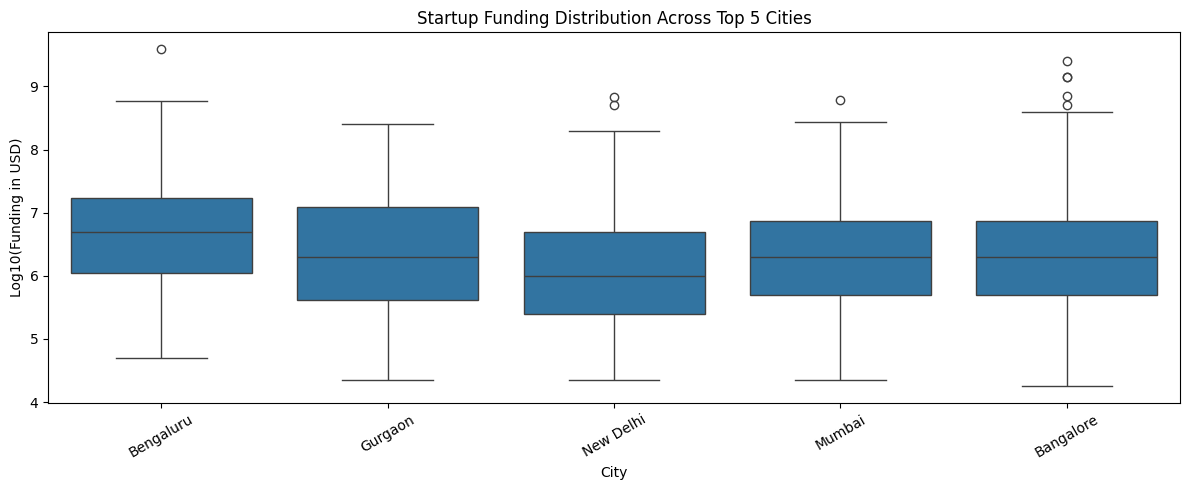

In [43]:
top_5_cities = city_analysis.head(5).index

city_funding = funding[
    funding[city_col].isin(top_5_cities)
].copy()

city_funding["Log_Funding"] = np.log10(
    city_funding["Funding_USD"]
)

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=city_funding,
    x=city_col,
    y="Log_Funding"
)

plt.title("Startup Funding Distribution Across Top 5 Cities")
plt.xlabel("City")
plt.ylabel("Log10(Funding in USD)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Which combinations of Indian cities and startup industries receive the largest investments?

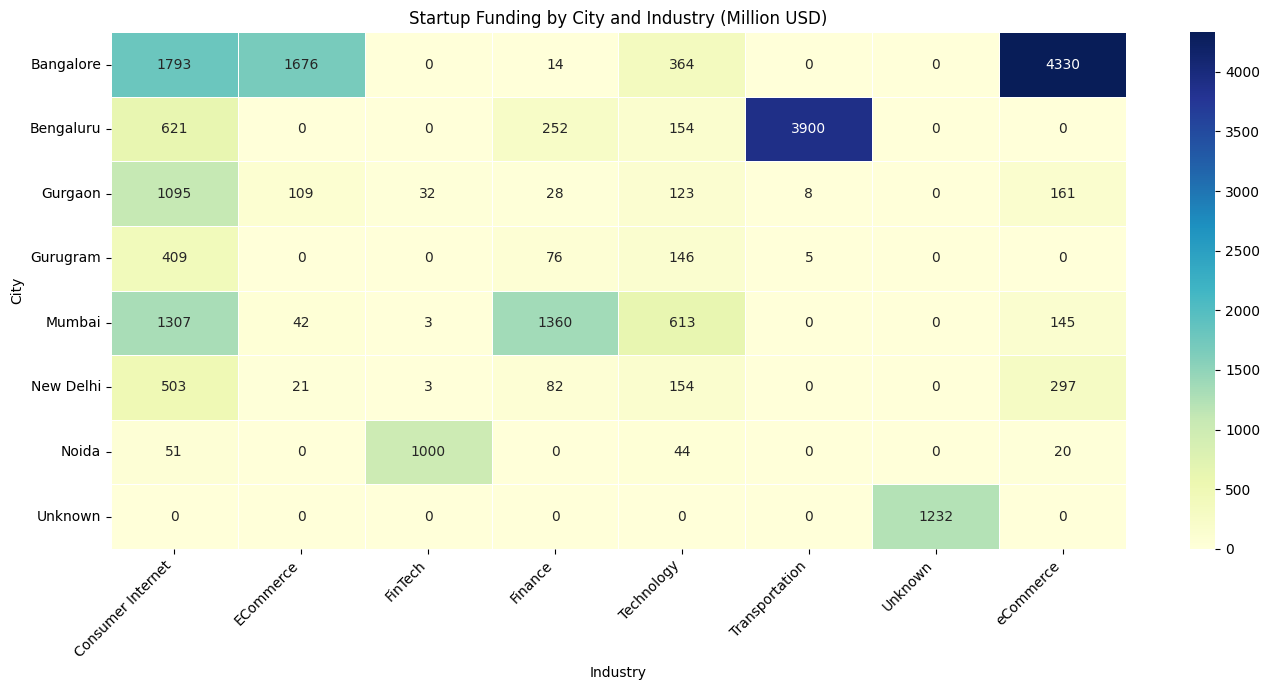

In [45]:
# Step 1: Select top cities and industries
top_cities = city_analysis.head(8).index
top_industries = industry_analysis.head(8).index

# Step 2: Filter records
filtered = funding[
    funding[city_col].isin(top_cities)
    & funding[industry_col].isin(top_industries)
].copy()

# Step 3: Ensure funding amounts are numeric
filtered["Funding_Million_USD"] = pd.to_numeric(
    filtered["Funding_Million_USD"],
    errors="coerce"
).astype(float)

# Step 4: Create pivot table
heatmap_data = filtered.pivot_table(
    index=city_col,
    columns=industry_col,
    values="Funding_Million_USD",
    aggfunc="sum",
    fill_value=0
)

# Step 5: Convert pivot table to float
heatmap_data = heatmap_data.astype(float)

# Step 6: Visualize
plt.figure(figsize=(14, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Startup Funding by City and Industry (Million USD)")
plt.xlabel("Industry")
plt.ylabel("City")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [46]:
print("=== CITY-INDUSTRY FUNDING ANALYSIS ===")

# Find the largest city-industry funding combination
ranking = heatmap_data.stack().sort_values(ascending=False)

if not ranking.empty:
    (top_city, top_industry), top_amount = ranking.index[0], ranking.iloc[0]

    print(f"Top City: {top_city}")
    print(f"Top Industry: {top_industry}")
    print(f"Total Funding: ${top_amount:,.2f} Million")

    print("\nConclusion:")
    print(
        f"{top_city} - {top_industry} has the highest disclosed "
        f"funding among the selected city-industry combinations."
    )

=== CITY-INDUSTRY FUNDING ANALYSIS ===
Top City: Bangalore
Top Industry: eCommerce
Total Funding: $4,330.25 Million

Conclusion:
Bangalore - eCommerce has the highest disclosed funding among the selected city-industry combinations.


In [47]:
print("=" * 65)
print("INDIAN STARTUP FUNDING — FINAL EDA REPORT")
print("=" * 65)

# 1. Dataset overview
print("\n1. DATASET OVERVIEW")
print(f"Total Original Records: {len(df):,}")
print(f"Valid Funding Transactions: {len(funding):,}")
print(f"Total Disclosed Funding: ${funding['Funding_USD'].sum()/1e9:,.2f} Billion")

# 2. Funding distribution
print("\n2. FUNDING DISTRIBUTION")
print(f"Average Funding: ${funding['Funding_USD'].mean()/1e6:,.2f} Million")
print(f"Median Funding: ${funding['Funding_USD'].median()/1e6:,.2f} Million")
print(f"Maximum Funding: ${funding['Funding_USD'].max()/1e6:,.2f} Million")

# 3. Leading cities
print("\n3. TOP 3 STARTUP CITIES")
for city, row in city_analysis.head(3).iterrows():
    print(f"{city}: ${row['Total_Funding']/1e6:,.2f} Million")

# 4. Leading industries
print("\n4. TOP 3 INDUSTRIES")
for industry, row in industry_analysis.head(3).iterrows():
    print(f"{industry}: ${row['Total_Funding']/1e6:,.2f} Million")

# 5. Outlier analysis
print("\n5. OUTLIER ANALYSIS")
outlier_count = funding["Is_Outlier"].sum()
outlier_pct = funding["Is_Outlier"].mean() * 100
outlier_funding = funding.loc[
    funding["Is_Outlier"], "Funding_USD"
].sum()

print(f"Outlier Transactions: {outlier_count:,} ({outlier_pct:.2f}%)")
print(f"Outlier Share of Funding: {outlier_funding/funding['Funding_USD'].sum()*100:.2f}%")

# 6. Funding trends
print("\n6. FUNDING TRENDS")
if not yearly_analysis.empty:
    peak_year = yearly_analysis["Total_Funding"].idxmax()
    print(f"Highest Funding Year: {int(peak_year)}")

# 7. Concentration
print("\n7. GEOGRAPHIC CONCENTRATION")
top_5_share = (
    city_analysis["Total_Funding"].head(5).sum()
    / city_analysis["Total_Funding"].sum()
) * 100

print(f"Top 5 Cities Funding Share: {top_5_share:.2f}%")

# 8. Recommendations
print("\n8. DATA SCIENTIST RECOMMENDATIONS")

if funding["Funding_USD"].mean() > funding["Funding_USD"].median():
    print("- Funding distribution has a mean above its median; report both.")

if top_5_share > 70:
    print("- Disclosed funding is highly concentrated in the top five city categories.")
else:
    print("- Funding is relatively less concentrated in the top five city categories.")

if outlier_pct > 5:
    print("- Investigate large funding transactions before excluding them.")

print("- Standardize industry and city labels before final reporting.")
print("- Validate funding currency, units, and historical coverage.")
print("- Avoid treating missing or undisclosed amounts as zero.")

print("\nEDA COMPLETED")

INDIAN STARTUP FUNDING — FINAL EDA REPORT

1. DATASET OVERVIEW
Total Original Records: 3,044
Valid Funding Transactions: 2,065
Total Disclosed Funding: $38.06 Billion

2. FUNDING DISTRIBUTION
Average Funding: $18.43 Million
Median Funding: $1.70 Million
Maximum Funding: $3,900.00 Million

3. TOP 3 STARTUP CITIES
Bangalore: $11,361.59 Million
Bengaluru: $7,098.58 Million
Mumbai: $4,921.19 Million

4. TOP 3 INDUSTRIES
Consumer Internet: $6,253.08 Million
eCommerce: $5,002.53 Million
Transportation: $3,916.63 Million

5. OUTLIER ANALYSIS
Outlier Transactions: 283 (13.70%)
Outlier Share of Funding: 85.21%

6. FUNDING TRENDS
Highest Funding Year: 2017

7. GEOGRAPHIC CONCENTRATION
Top 5 Cities Funding Share: 77.26%

8. DATA SCIENTIST RECOMMENDATIONS
- Funding distribution has a mean above its median; report both.
- Disclosed funding is highly concentrated in the top five city categories.
- Investigate large funding transactions before excluding them.
- Standardize industry and city labels be